In [ ]:
!pip install transformers torch scikit-learn

In [ ]:
!pip install "datasets<2.20.0"

INFO: pip is looking at multiple versions of multiprocess to determine which version is compatible with other requirements. This could take a while.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 542.1/542.1 kB 47.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 116.3/116.3 kB 15.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 172.0/172.0 kB 8.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 146.7/146.7 kB 17.6 MB/s eta 0:00:00
  Attempting uninstall: fsspec
    Found existing installation: fsspec 2025.12.0
    Uninstalling fsspec-2025.12.0:
      Successfully uninstalled fsspec-2025.12.0
  Attempting uninstall: dill
    Found existing installation: dill 0.4.1
    Uninstalling dill-0.4.1:
      Successfully uninstalled dill-0.4.1
  Attempting uninstall: multiprocess
    Found existing installation: multiprocess 0.70.19
    Uninstalling multiprocess-0.70.19:
      Successfully uninstalled multiprocess-0.70.19
  Attempting uninstall: datasets
    F

In [ ]:
!pip install lime

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 24.7 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283913 sha256=ebd88fbb0f31652113cc02dab8d36b4e7d45cc224f89d921f1596247718284bd
  Stored in directory: /root/.cache/pip/wheels/7c/04/5c/157dc9106512a6c7a30653ec064490c94a49e0fc8f63d19ab9
Successfully built lime


In [ ]:
!pip install matplotlib seaborn

In [ ]:
# semente semente semente semente
import os
import random
import re
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix, roc_curve, auc
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from transformers import RobertaTokenizer, RobertaForSequenceClassification
from datasets import load_dataset
from lime.lime_text import LimeTextExplainer

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    os.environ['PYTHONHASHSEED'] = str(seed)
    print(f"[OK] semente fixada em: {seed}")

set_seed(42)

[OK] semente fixada em: 42


In [ ]:
# baixando e limpando os dadps
print("baixando o dataset")
dataset_hf = load_dataset("mrjunos/depression-reddit-cleaned", trust_remote_code=True)
df = pd.DataFrame(dataset_hf['train'])
df = df.rename(columns={'text': 'texto_limpo'})

def limpar_texto_redes_sociais(texto):
    if not isinstance(texto, str):
        return ""
    texto = texto.lower()
    texto = re.sub(r'http\S+|www\S+|https\S+', '', texto, flags=re.MULTILINE)
    texto = re.sub(r'\@\w+', '', texto)
    texto = re.sub(r'[^\w\s]', '', texto)
    texto = re.sub(r'\s+', ' ', texto).strip()
    return texto

print("limpando")
df['texto_limpo'] = df['texto_limpo'].apply(limpar_texto_redes_sociais)

qtd_antes = len(df)
df = df[df['texto_limpo'].str.len() > 5].copy()
df = df.drop_duplicates(subset=['texto_limpo']).reset_index(drop=True)
qtd_depois = len(df)

print(f"{qtd_antes - qtd_depois} textos duplicados/vazios excluidos")
print(f"total final de registros: {qtd_depois}")

baixando o dataset


Generating train split:   0%|          | 0/7731 [00:00<?, ? examples/s]

limpando
82 textos duplicados/vazios excluidos
total final de registros: 7649


In [ ]:
#dividindo dados
df_treino, df_teste = train_test_split(
    df,
    test_size=0.20,
    random_state=42,
    stratify=df['label']
)
print(f"Treino: {len(df_treino)} | Teste: {len(df_teste)}")

print("carregando Tokenizador Byte-Level (roberta-base)")
tokenizer = RobertaTokenizer.from_pretrained('roberta-base')
train_encodings = tokenizer(df_treino['texto_limpo'].tolist(), truncation=True, padding='max_length', max_length=128)
test_encodings = tokenizer(df_teste['texto_limpo'].tolist(), truncation=True, padding='max_length', max_length=128)
print("tokenização concluída")

Treino: 6119 | Teste: 1530
carregando Tokenizador Byte-Level (roberta-base)


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

tokenização concluída


In [ ]:
#organização
class RedditDepressionDataset(Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    def __getitem__(self, idx):
        item = {key: torch.tensor(val[idx]) for key, val in self.encodings.items()}
        item['labels'] = torch.tensor(self.labels[idx], dtype=torch.long)
        return item

    def __len__(self):
        return len(self.labels)

print("criando os objetos")
train_dataset = RedditDepressionDataset(train_encodings, df_treino['label'].tolist())
test_dataset = RedditDepressionDataset(test_encodings, df_teste['label'].tolist())

print("empacotando os dados em lotes (Batch Size = 32)")
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)
print(f"Treino: {len(train_loader)} lotes | Teste: {len(test_loader)} lotes.\n")

print(" vendo o Primeiro Lote")
primeiro_lote = next(iter(train_loader))
print("Chaves contidas no lote: ", primeiro_lote.keys())
print("Dimensão dos input_ids: ", primeiro_lote['input_ids'].shape)
print("Dimensão da attention_mask: ", primeiro_lote['attention_mask'].shape)
print("Dimensão dos rótulos: ", primeiro_lote['labels'].shape)
print("\nRótulos das 32 amostras deste lote (0 = Não Depressivo, 1 = Depressivo):")
print(primeiro_lote['labels'])

criando os objetos
empacotando os dados em lotes (Batch Size = 32)
Treino: 192 lotes | Teste: 48 lotes.

 vendo o Primeiro Lote
Chaves contidas no lote:  dict_keys(['input_ids', 'attention_mask', 'labels'])
Dimensão dos input_ids:  torch.Size([32, 128])
Dimensão da attention_mask:  torch.Size([32, 128])
Dimensão dos rótulos:  torch.Size([32])

Rótulos das 32 amostras deste lote (0 = Não Depressivo, 1 = Depressivo):
tensor([1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 1, 1,
        0, 1, 1, 1, 0, 1, 0, 0])


In [ ]:
# carregando modelo
print("baixando e instanciando o modelo")
modelo_roberta = RobertaForSequenceClassification.from_pretrained('roberta-base', num_labels=2)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
modelo_roberta.to(device)
print(f"Modelo enviado para : {device}")

baixando e instanciando o modelo


config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  499MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
classifier.dense.bias      | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.out_proj.weight | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Modelo enviado para : cuda


In [ ]:
#treinamento
otimizador = AdamW(modelo_roberta.parameters(), lr=2e-5)
epochs = 3

print("iniciando o treinamento")
for epoch in range(epochs):
    modelo_roberta.train()
    total_loss = 0

    for step, batch in enumerate(train_loader):
        otimizador.zero_grad()

        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['labels'].to(device)

        outputs = modelo_roberta(input_ids=input_ids, attention_mask=attention_mask, labels=labels)
        loss = outputs.loss
        total_loss += loss.item()

        loss.backward()
        otimizador.step()

        if step % 50 == 0:
            print(f"Época {epoch + 1}/{epochs} | Lote {step}/{len(train_loader)} | Loss: {loss.item():.4f}")

    print(f"--- Fim da Época {epoch + 1} | Perda Média: {total_loss / len(train_loader):.4f} ---")

print("treinamento  concluído")

iniciando o treinamento
Época 1/3 | Lote 0/192 | Loss: 0.7152
Época 1/3 | Lote 50/192 | Loss: 0.1860
Época 1/3 | Lote 100/192 | Loss: 0.1746
Época 1/3 | Lote 150/192 | Loss: 0.1341
--- Fim da Época 1 | Perda Média: 0.1366 ---
Época 2/3 | Lote 0/192 | Loss: 0.0072
Época 2/3 | Lote 50/192 | Loss: 0.0481
Época 2/3 | Lote 100/192 | Loss: 0.0568
Época 2/3 | Lote 150/192 | Loss: 0.0041
--- Fim da Época 2 | Perda Média: 0.0435 ---
Época 3/3 | Lote 0/192 | Loss: 0.0179
Época 3/3 | Lote 50/192 | Loss: 0.0016
Época 3/3 | Lote 100/192 | Loss: 0.0056
Época 3/3 | Lote 150/192 | Loss: 0.0736
--- Fim da Época 3 | Perda Média: 0.0247 ---
treinamento  concluído


Acurácia:  98.17%
Precisão:  0.9801
Recall:    0.9827
F1-Score:  0.9814

                precision    recall  f1-score   support

Não Depressivo       0.98      0.98      0.98       778
    Depressivo       0.98      0.98      0.98       752

      accuracy                           0.98      1530
     macro avg       0.98      0.98      0.98      1530
  weighted avg       0.98      0.98      0.98      1530



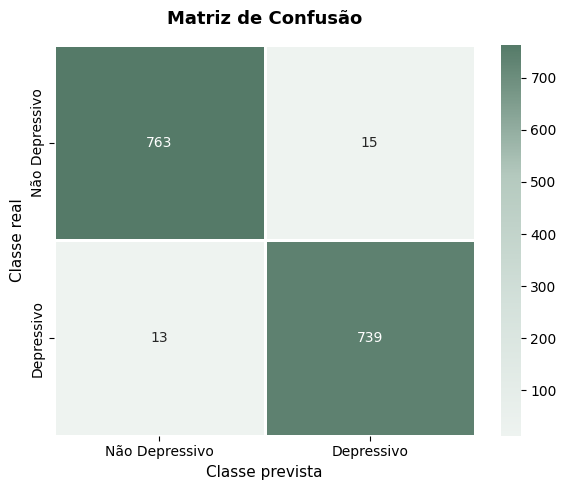

In [ ]:
# avaliação
modelo_roberta.eval()
previsoes_finais, rotulos_reais = [], []

with torch.no_grad():
    for batch in test_loader:
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['labels'].to(device)

        outputs = modelo_roberta(input_ids=input_ids, attention_mask=attention_mask)
        preds = torch.argmax(outputs.logits, dim=1)

        previsoes_finais.extend(preds.cpu().numpy())
        rotulos_reais.extend(labels.cpu().numpy())

acuracia = accuracy_score(rotulos_reais, previsoes_finais)
prec = precision_score(rotulos_reais, previsoes_finais)
rec = recall_score(rotulos_reais, previsoes_finais)
f1 = f1_score(rotulos_reais, previsoes_finais)


print(f"Acurácia:  {acuracia * 100:.2f}%")
print(f"Precisão:  {prec:.4f}")
print(f"Recall:    {rec:.4f}")
print(f"F1-Score:  {f1:.4f}\n")
print(classification_report(rotulos_reais, previsoes_finais, target_names=['Não Depressivo', 'Depressivo']))

cm = confusion_matrix(rotulos_reais, previsoes_finais)

cor_roberta1 = "#557A68"
cores_roberta1 = ["#EEF3F0", "#D4E1DB", "#B4C9BE", cor_roberta1]
cmap_roberta1 = LinearSegmentedColormap.from_list("RoBERTa1", cores_roberta1)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap=cmap_roberta1,
    xticklabels=['Não Depressivo', 'Depressivo'],
    yticklabels=['Não Depressivo', 'Depressivo'],
    linewidths=1,
    linecolor='white'
)
plt.xlabel('Classe prevista', fontsize=11)
plt.ylabel('Classe real', fontsize=11)
plt.title('Matriz de Confusão', fontsize=13, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

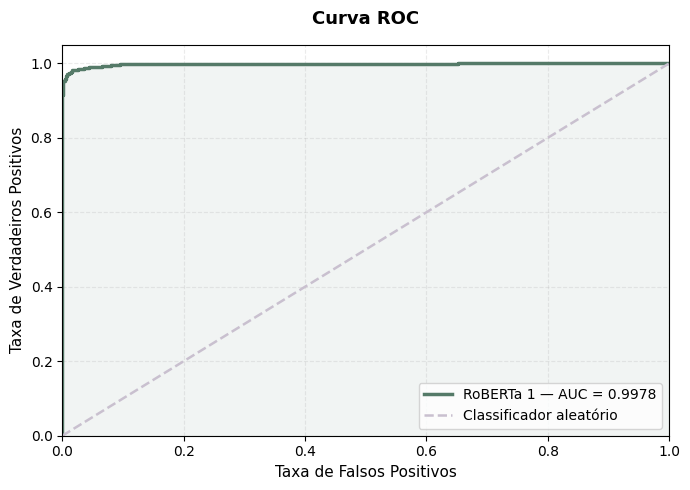

AUC Final: 0.9978


In [ ]:
# roc e auc
probabilidades, verdadeiros = [], []

modelo_roberta.eval()
with torch.no_grad():
    for batch in test_loader:
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['labels'].to(device)

        outputs = modelo_roberta(input_ids=input_ids, attention_mask=attention_mask)
        probs = F.softmax(outputs.logits, dim=1)

        probabilidades.extend(probs[:, 1].cpu().numpy())
        verdadeiros.extend(labels.cpu().numpy())

fpr, tpr, limiares = roc_curve(verdadeiros, probabilidades)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, color="#557A68", lw=2.5, label=f'RoBERTa 1 — AUC = {roc_auc:.4f}')
plt.fill_between(fpr, tpr, alpha=0.08, color="#557A68")
plt.plot([0, 1], [0, 1], color="#C9C0CF", lw=1.8, linestyle='--', label='Classificador aleatório')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Taxa de Falsos Positivos', fontsize=11)
plt.ylabel('Taxa de Verdadeiros Positivos', fontsize=11)
plt.title('Curva ROC', fontsize=13, fontweight='bold', pad=15)
plt.legend(loc="lower right", frameon=True)
plt.grid(alpha=0.25, linestyle='--')
plt.tight_layout()
plt.show()

print(f"AUC Final: {roc_auc:.4f}")

moony 9 huggggs i m glad you re here to help me through this he wa my favourite character the white house suck for stealing him

Rótulo Real: 0 (Não Depressivo)



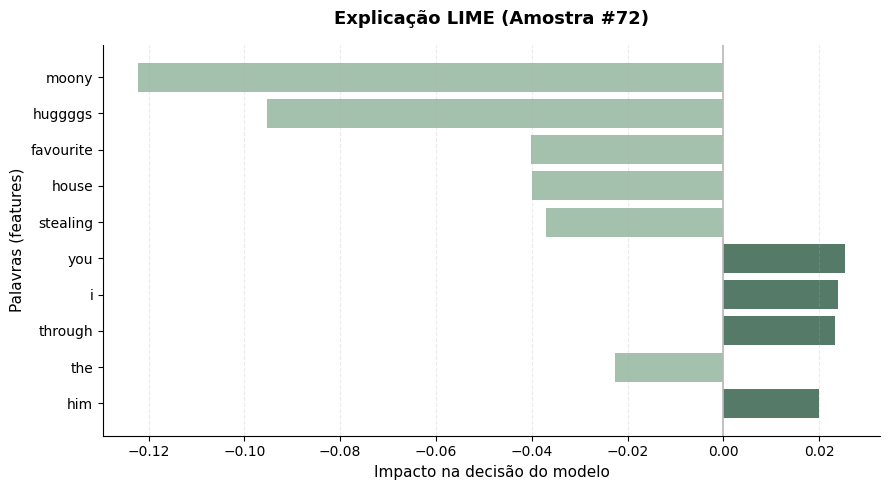

In [ ]:
# LIME
from lime.lime_text import LimeTextExplainer
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from IPython.display import display, HTML

def predict_probs_lime(texts):
    modelo_roberta.eval()
    todas_probs = []
    for i in range(0, len(texts), 32):
        lote_textos = texts[i:i + 32]
        inputs = tokenizer(lote_textos, padding='max_length', truncation=True, max_length=128, return_tensors="pt")
        input_ids = inputs['input_ids'].to(device)
        attention_mask = inputs['attention_mask'].to(device)
        with torch.no_grad():
            outputs = modelo_roberta(input_ids=input_ids, attention_mask=attention_mask)
            probs = F.softmax(outputs.logits, dim=1)
            todas_probs.append(probs.cpu().numpy())
    return np.vstack(todas_probs)

explainer = LimeTextExplainer(class_names=['Não Depressivo', 'Depressivo'], random_state=42)

idx = 72
texto_amostra = str(df_teste.iloc[idx]['texto_limpo'])
rotulo_real = int(df_teste.iloc[idx]['label'])


print(f"{texto_amostra}\n")
print(f"Rótulo Real: {rotulo_real} ({'Depressivo' if rotulo_real == 1 else 'Não Depressivo'})\n")

exp = explainer.explain_instance(texto_amostra, predict_probs_lime, num_features=10, num_samples=500)

lista_features = exp.as_list()
palavras = [item[0] for item in lista_features]
pesos = np.array([item[1] for item in lista_features], dtype=np.float64)

cor_roberta1_pos = "#557A68"
cor_roberta1_neg = "#A3C1AD"
cor_zero = "#B8B8B8"

plt.figure(figsize=(9, 5))
cores = [cor_roberta1_pos if peso > 0 else cor_roberta1_neg for peso in pesos]
plt.barh(palavras[::-1], pesos[::-1], color=cores[::-1], edgecolor='none')
plt.axvline(0, color=cor_zero, linewidth=1.2)
plt.xlabel('Impacto na decisão do modelo', fontsize=11)
plt.ylabel('Palavras (features)', fontsize=11)
plt.title(f'Explicação LIME (Amostra #{idx})', fontsize=13, fontweight='bold', pad=15)
plt.grid(axis='x', linestyle='--', alpha=0.25)
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.show()

css_roberta1_darkmode = """ """
display(HTML(css_roberta1_darkmode))
exp.show_in_notebook(text=True)